# Interpolación lineal

La interpolación lineal es un método matemático que permite estimar un valor desconocido que se encuentra *entre* dos puntos conocidos $(x_1, y_1)$ y $(x_2, y_2)$, asumiendo que el cambio entre ellos es una línea recta.

Para encontrar el valor correspondiente a un punto $x$ con $x_1 \leq x \leq x_2$:

$$
y = y_1 + \frac{y_2 - y_1}{x_2 - x_1} \cdot (x - x_1)
$$

### Ejemplo

Tenemos una tabla con los siguientes datos:

| | x | y |
|---|---|---|
| 0 | 200 | 15 |
| 1 | 300 | 20 |

Queremos saber el valor que tomará $y$ cuando $x = 250$.
Para ello usamos la fórmula anterior; para que sea fácil de repetir después, la dejamos dentro de una función.

In [1]:
def interpolLin(x, x1, x2, y1, y2):
    """Interpolación lineal de y en x, con x1 <= x <= x2."""
    return y1 + (y2 - y1) / (x2 - x1) * (x - x1)

Ingresamos los valores de la tabla y calculamos el nuevo valor de $y$:

In [2]:
import pandas as pd

x1, y1 = 200, 15
x2, y2 = 300, 20
x = 250

y = interpolLin(x, x1, x2, y1, y2)

df = pd.DataFrame({"x": [x1, x, x2], "y": [y1, y, y2]})
df

,x,y
0,200,15.0
1,250,17.5
2,300,20.0


Comprobación: $y = 15 + \frac{20-15}{300-200}\cdot(250-200) = 15 + 0.05 \cdot 50 = 17.5$

### Gráfica

Podemos dibujar la recta con la función `draw` del archivo personal, es el mismo que utilizo en los otros cuadernos. Como `interpolLin` solo usa operaciones aritméticas, funciona directamente con arreglos de NumPy.

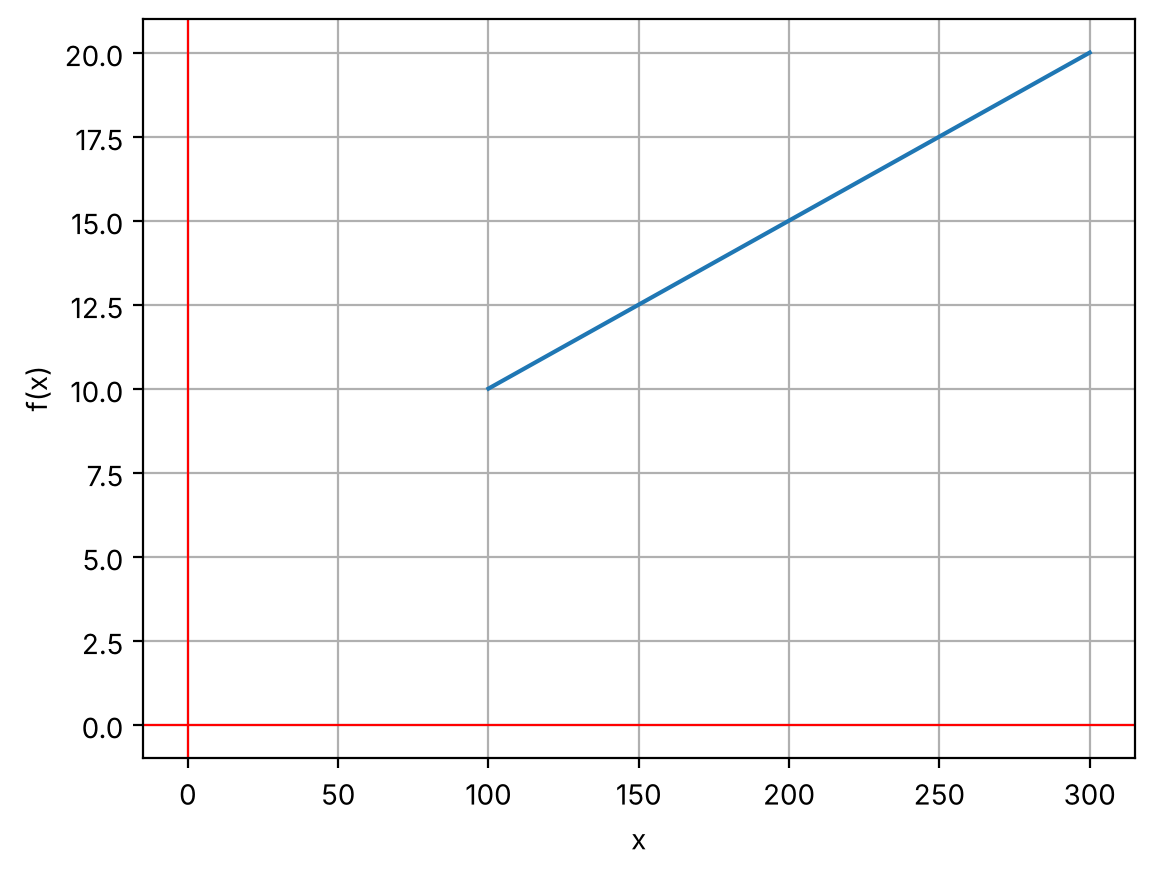

In [ ]:
from personal import draw
draw(lambda x: interpolLin(x, x1, x2, y1, y2), x_min=100, x_max=300)

### Interpolación vs extrapolación

Si quisiéramos $y$ cuando $x = 100$, ese valor ya no está entre 200 y 300, por lo que no sería interpolación sino **extrapolación**. La fórmula devuelve $y = 10$, pero es menos confiable, porque supone que la recta sigue igual fuera del intervalo donde conocemos los datos. Aun asi la formula es la misma y el resultado es " correcto " (como linea recta) aunque menos confiable. 

In [5]:
interpolLin(100, x1, x2, y1, y2)  # extrapolación

10.0

### Observaciones

Por la simplicidad de los datos utilizados, el valor es casi intuitivo. La interpolación lineal produce un resultado que pasa exactamente por los dos puntos conocidos; de hecho, existe una y solo una recta que pasa por ellos.

A diferencia de otros métodos, la forma de reducir el error no es mediante la iteración: los valores no convergen, y repetir la fórmula con el mismo $x$ y los mismos puntos dará exactamente el mismo resultado. La mejor manera de mejorar la estimación es conseguir datos más cercanos entre sí, es decir, que la separación entre $x_1$ y $x_2$ sea menor.

La diferencia entre la recta $P_1(x)$ y la función real $f(x)$ en un punto $x$ es el **error de truncamiento**:

$$E_t(x) = f(x) - P_1(x)$$

Si $f$ es dos veces derivable en $[x_1, x_2]$, este error se puede acotar así:

$$|E_t(x)| \leq \frac{(x_2 - x_1)^2}{8} \max_{[x_1,x_2]} |f''(x)|$$

Al reducir la separación entre los puntos, el error disminuye cuadráticamente.